In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LassoCV

# Data Preprocessing and Model Training

This notebook processes Ethiopia LSMS (Living Standards Measurement Survey) 2015 data to create a consumption prediction model for poverty targeting.

**Pipeline:**
1. Load and clean survey data (consumption, assets, housing, ...)
2. Merge into a single household-level dataset
3. Train a LASSO model to predict consumption from observable characteristics

**Data source:** The survey data can be downloaded from the LSMS program [here](https://microdata.worldbank.org/index.php/catalog/2783).

**Output:** `survey2015.csv` — processed dataset with predictions


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

root = '/content/drive/MyDrive/Fall Quarter 2026/DSC 180A/ETH_2015_ESS_v03_M_STATA/'

Mounted at /content/drive


## Preprocessing


### Consumption data


In [ ]:
# Read consumption data, get HHID + consumption HH weight columns
cons = pd.read_stata(root + 'cons_agg_w3.dta')
cons = cons[['household_id', 'nom_totcons_aeq', 'adulteq']]
cons.columns = ['hhid', 'Per Capita Consumption', 'Adults']

# Construct total consumption from per capita consumption
cons['Consumption'] = cons['Per Capita Consumption']*cons['Adults']
cons = cons[['hhid', 'Consumption']]

# Drop any households with missing ID or missing consumption
cons['hhid'] = cons['hhid'].apply(lambda x: np.nan if x == '' else x)
cons = cons.dropna(how='any')

# Convert to Birr per year to USD PPP per year
exchange_rate = 20.13
cons['Consumption'] = cons['Consumption']/exchange_rate
print('Households with consumption data: %i' % len(cons))


Households with consumption data: 4717


### Asset data


In [ ]:
# Get asset data from asset module
assets = pd.read_stata(root + 'Household/sect10_hh_w3.dta')
assets = assets[['household_id', 'hh_s10q00', 'hh_s10q01']]
assets['household_id'] = assets['household_id'].apply(lambda x: np.nan if x == '' else x)

# Drop households missing ID and duplicate records
assets = assets.dropna(subset=['household_id'])
assets = assets.drop_duplicates(subset=['household_id', 'hh_s10q00'])

assets[assets['household_id'].isin(['13010100303004', '01050100105031', '13010100303032'])]

# Pivot to per-household dataset
assets = assets.pivot(columns=['hh_s10q00'], index=['household_id'])
assets.columns = [str(c[1]) for c in assets.columns]
assets['hhid'] = assets.index
assets.index = range(len(assets))
assets = assets.fillna(0)
assets.columns = ['Kerosene stove', 'Gas stove', 'Electric stove', 'Blanket', 'Bed', 'Clock', 'Telephone',
                 'Mobile phone', 'Radio', 'TV', 'CD/DVD', 'Satellite dish', 'Sofa', 'Bicycle', 'Motorcycle',
                 'Hand cart', 'Animal-drawn cart', 'Sewing machine', 'Weaving equipment', 'Mitad',
                  'Energy-saving stove', 'Refridgerator', 'Car', 'Jewels', 'Wardrobe', 'Shelf', 'Biogas stove',
                 'Water storage pit', 'Mofer and kember', 'Sickle', 'Axe', 'Pick axe', 'Plough (traditional)',
                 'Plough (modern)', 'Water pump', 'hhid']
print('Households with asset data: %i' % len(assets))


Households with asset data: 4951


### Housing data


In [ ]:
# Get housing data from housing module
housing = pd.read_stata(root + 'Household/sect9_hh_w3.dta', convert_categoricals=False)
housing = housing[['household_id', 'hh_s9q03', 'hh_s9q04', 'hh_s9q05', 'hh_s9q06', 'hh_s9q07', 'hh_s9q08',
                   'hh_s9q09',  'hh_s9q12', 'hh_s9q17', 'hh_s9q19_a', 'hh_s9q21']]
colnames = ['hhid', 'Ownership status', 'Rooms', 'Walls', 'Roof', 'Floor', 'Kitchen', 'Oven', 'Garbage',
            'Other houses', 'Lighting fuel', 'Cooking fuel']
housing.columns = colnames

# Drop households missing IDs, no other column has missingness
housing['hhid'] = housing['hhid'].apply(lambda x: np.nan if x == '' else x)
housing = housing.dropna()

print('Households with housing data: %i' % len(housing))


Households with housing data: 4954


### Demographic data


In [ ]:
# Get demographic data from individual rsoter module
demographics = pd.read_stata(root + 'Household/sect1_hh_w3.dta', convert_categoricals=False)
demographics = demographics[['household_id', 'hh_s1q02', 'hh_s1q03', 'hh_s1q04a', 'hh_s1q04b', 'hh_s1q08']]
demographics.columns = ['hhid', 'hhh', 'gender', 'age1', 'age2', 'married']

# Get age -- use age of household head if available, infer household head age as second member's age if not
demographics['age'] = demographics['age1'].fillna(demographics['age2'])

# Add missing category to martical status
demographics['married'] = demographics['married'].fillna(0)

# Drop any rows missing ID
demographics['hhid'] = demographics['hhid'].apply(lambda x: np.nan if x == '' else x)
demographics = demographics.dropna(subset=['hhid'])

# Create dataframe of household head data
hhh = demographics[demographics['hhh'] == 1].copy()
hhh = hhh[['hhid', 'gender', 'age', 'married']]
hhh.columns = ['hhid', 'HHH gender', 'HHH age', 'HHH married']

# Create dataframe with number of children in household
children = demographics[demographics['age'] < 5].copy()
children = children[['hhid', 'gender']].groupby('hhid', as_index=False).agg('count')\
    .rename({'gender':'Children'}, axis=1)

# Create dataframe with other misc demographic data -- region, number of members
geo = pd.read_stata(root + 'cons_agg_w3.dta', convert_categoricals=False)
geo = geo[['household_id', 'saq01', 'hh_size']]
geo.columns = ['hhid', 'region', 'hh_size']

# Merge all demographic data together
demographics = geo.merge(hhh, on='hhid', how='left').merge(children, on='hhid', how='left')
demographics['Children'] = demographics['Children'].fillna(0)
demographics = demographics.dropna()
print('Households with demographic data: %i' % len(demographics))


Households with demographic data: 4953


### Education data


In [ ]:
# Get IDs for just household heads
hhh = pd.read_stata(root + '/Household/sect1_hh_w3.dta', convert_categoricals=False)
hhh = hhh[['household_id', 'individual_id2', 'hh_s1q02']]
hhh.columns = ['hhid', 'iid', 'hhh']
hhh = hhh[hhh['hhh'] == 1][['hhid', 'iid']]

# Read education data from individual roster module
education = pd.read_stata(root + '/Household/sect2_hh_w3.dta', convert_categoricals=False)
education = education[['individual_id2', 'hh_s2q02', 'hh_s2q03', 'hh_s2q05']]
education.columns = ['iid', 'literate', 'school', 'level_school']

# Merge education data to IDs to get education data for just household heads
education = education.merge(hhh, on='iid', how='inner').drop('iid', axis=1)

# Recode literacy and education variables
education['literate'] = 1 - (education['literate'] - 1)
education['level_school'] = np.where(education['school'] == 2, -1, education['level_school'])
education = education.drop('school', axis=1)
education['level_school'] = education['level_school'].fillna(-1)

print('Households with education data: %i' % len(education))


Households with education data: 4934


### Merge all data together


In [ ]:
# Combine together all dataframes (HH need to have consumption data, can have other data missing)
df = cons.merge(demographics, on='hhid', how='left').merge(housing, on='hhid', how='left')\
    .merge(assets, on='hhid', how='left').merge(education, on='hhid', how='left')\
    .dropna()\
    .drop_duplicates(subset=['hhid'])

# Get outcome and feature variables
outcome = 'Consumption'
x_vars = [c for c in df.columns if c not in ['hhid', outcome]]

# Define type for each feature variable manually
x_var_types = ['cat', 'int', 'bin', 'int', 'cat', 'int', 'cat', 'int', 'cat', 'cat', 'cat', 'cat',
              'cat', 'cat', 'bin', 'cat', 'cat'] + ['int']*(len(assets.columns) - 1) + ['bin', 'cat']

for v, var in enumerate(x_vars):

    # Check binary variables for having exactly 2 values, and convert values to 0 and 1
    if x_var_types[v] == 'bin':
        if len(df[var].unique()) != 2:
            print('Error: Unique values in column ' + var + ' not equal to 2')
        if 2 in df[var].unique():
            df[var] = df[var] - 1

    # Winsorize then scale continuous variables, and drop any that have 100% missingness or are constant
    elif x_var_types[v] == 'int':
        cutoff = np.percentile(df[var], 99)
        df[var] = df[var].apply(lambda x: cutoff if x > cutoff else x)
        df[var] = (df[var] - df[var].min())/(df[var].max() - df[var].min())
        if df[var].isnull().mean() == 1:
            df = df.drop(var, axis=1)

# Combine any categories in categorical variables with <1% of observations into an "other" category
# and one hot encode
cat_vars = [x_vars[v] for v in range(len(x_vars)) if x_var_types[v] == 'cat']
for cat_var in cat_vars:
    to_remove = []
    grouped = pd.DataFrame(df.groupby(cat_var).count()['hhid']/len(df))
    for value, share in grouped.iterrows():
        if share.iloc[0] < 0.01:
            to_remove.append(value)
    df[cat_var] = df[cat_var].apply(lambda x: 9999 if x in to_remove else x)
df = pd.get_dummies(df, columns=cat_vars, drop_first=True)

df.to_csv('survey2015.csv', index=False)
print('Households in final dataset: %i' % len(df))


Households in final dataset: 4694


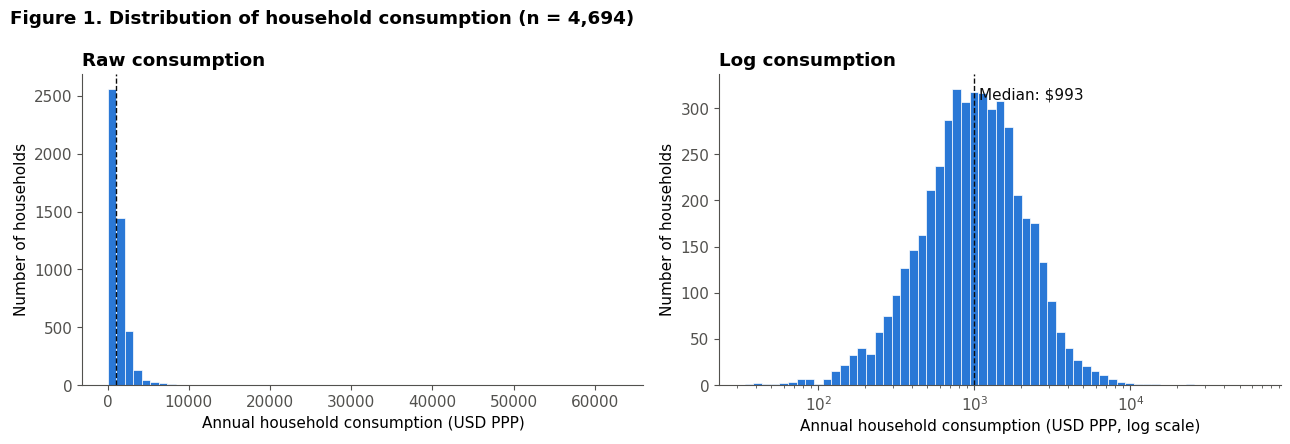

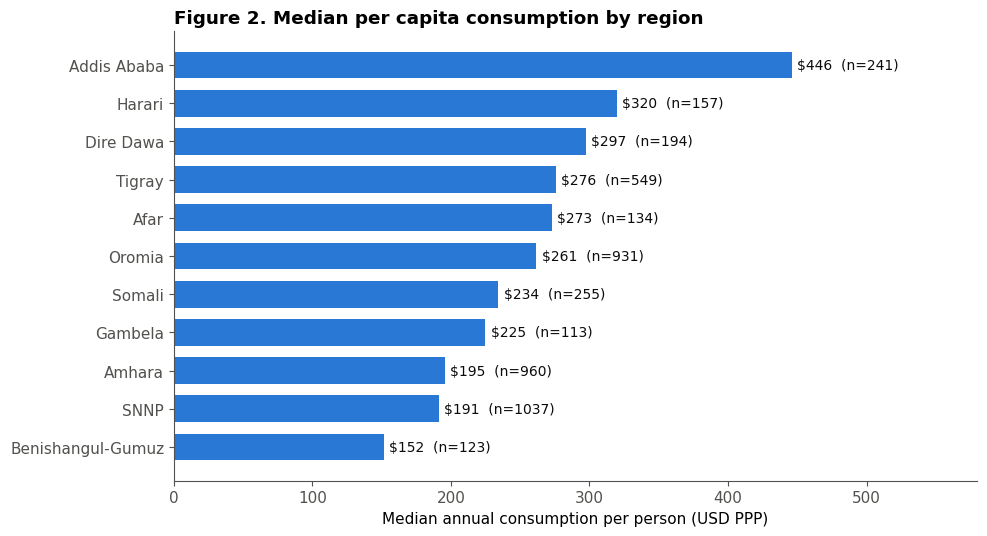

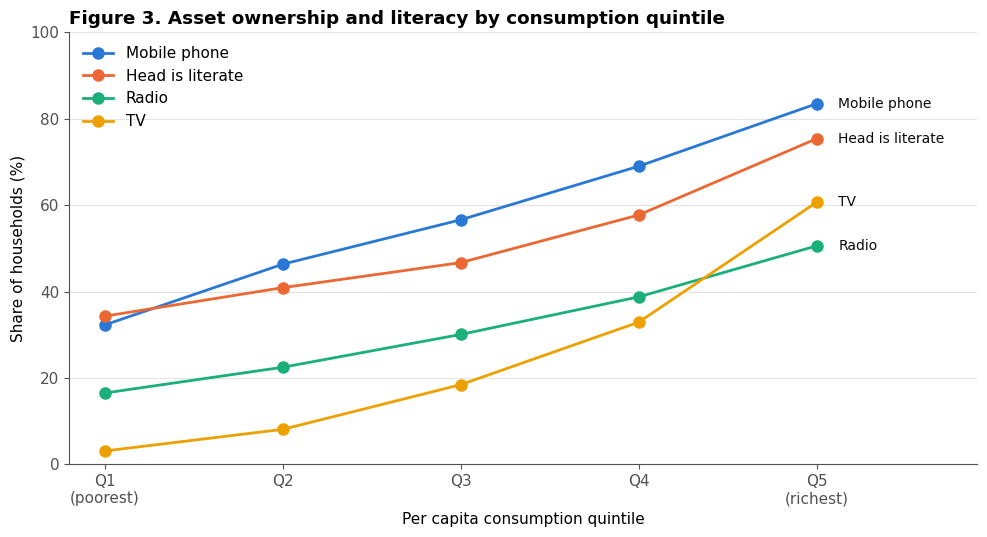

In [ ]:
# Visualizations: rebuild an unscaled copy of the merged data (df itself is already scaled and one-hot encoded)
import matplotlib.pyplot as plt

viz = cons.merge(demographics, on='hhid', how='inner').merge(assets, on='hhid', how='inner').merge(education, on='hhid', how='inner').drop_duplicates(subset=['hhid'])
viz['Per Capita'] = viz['Consumption'] / viz['hh_size']
region_names = {1: 'Tigray', 2: 'Afar', 3: 'Amhara', 4: 'Oromia', 5: 'Somali', 6: 'Benishangul-Gumuz', 7: 'SNNP', 12: 'Gambela', 13: 'Harari', 14: 'Addis Ababa', 15: 'Dire Dawa'}
viz['Region'] = pd.to_numeric(viz['region']).map(region_names)

BLUE, ORANGE, AQUA, YELLOW, INK, MUTED = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#0b0b0b', '#52514e'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED, 'font.size': 11, 'axes.titleweight': 'bold'})

# Figure 1: distribution of household consumption, raw vs. log scale
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
med = viz['Consumption'].median()
axes[0].hist(viz['Consumption'], bins=60, color=BLUE, edgecolor='white', linewidth=0.5)
log_bins = np.logspace(np.log10(viz['Consumption'].min()), np.log10(viz['Consumption'].max()), 60)
axes[1].hist(viz['Consumption'], bins=log_bins, color=BLUE, edgecolor='white', linewidth=0.5)
axes[1].set_xscale('log')
for ax in axes:
    ax.axvline(med, color=INK, linestyle='--', linewidth=1)
    ax.set_ylabel('Number of households')
axes[0].set_xlabel('Annual household consumption (USD PPP)')
axes[1].set_xlabel('Annual household consumption (USD PPP, log scale)')
axes[0].set_title('Raw consumption', loc='left')
axes[1].set_title('Log consumption', loc='left')
axes[1].text(med * 1.08, axes[1].get_ylim()[1] * 0.92, f'Median: ${med:,.0f}', color=INK)
fig.suptitle(f'Figure 1. Distribution of household consumption (n = {len(viz):,})', x=0.01, ha='left', fontweight='bold')
plt.tight_layout()
plt.show()

# Figure 2: median per capita consumption by region
by_region = viz.groupby('Region')['Per Capita'].agg(['median', 'count']).sort_values('median')
fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.barh(by_region.index, by_region['median'], color=BLUE, height=0.7)
ax.bar_label(bars, labels=[f'${m:,.0f}  (n={n})' for m, n in zip(by_region['median'], by_region['count'])], padding=4, color=INK, fontsize=10)
ax.set_xlabel('Median annual consumption per person (USD PPP)')
ax.set_xlim(0, by_region['median'].max() * 1.3)
ax.set_title('Figure 2. Median per capita consumption by region', loc='left')
plt.tight_layout()
plt.show()

# Figure 3: asset ownership and literacy across per capita consumption quintiles
viz['Quintile'] = pd.qcut(viz['Per Capita'], 5, labels=['Q1\n(poorest)', 'Q2', 'Q3', 'Q4', 'Q5\n(richest)'])
indicators = {'Mobile phone': viz['Mobile phone'] > 0, 'Head is literate': viz['literate'] == 1, 'Radio': viz['Radio'] > 0, 'TV': viz['TV'] > 0}
shares = pd.DataFrame({k: v.groupby(viz['Quintile'], observed=True).mean() * 100 for k, v in indicators.items()})
fig, ax = plt.subplots(figsize=(10, 5.5))
for c, col in zip(shares.columns, [BLUE, ORANGE, AQUA, YELLOW]):
    ax.plot(range(5), shares[c], marker='o', markersize=8, linewidth=2, color=col, label=c)
    ax.text(4.12, shares[c].iloc[-1], c, color=INK, va='center', fontsize=10)
ax.set_xticks(range(5))
ax.set_xticklabels(shares.index)
ax.set_xlim(-0.2, 4.9)
ax.set_ylim(0, 100)
ax.set_ylabel('Share of households (%)')
ax.set_xlabel('Per capita consumption quintile')
ax.grid(axis='y', color='#e5e4e0', linewidth=0.8)
ax.legend(frameon=False, loc='upper left')
ax.set_title('Figure 3. Asset ownership and literacy by consumption quintile', loc='left')
plt.tight_layout()
plt.show()

## Model Training


In [ ]:
def train_consumption_model(random_state=0):
    """Train LASSO model to predict consumption from survey features.

    Returns:
        DataFrame with columns 'y_test' (actual) and 'yhat_test' (predicted),
        both in USD PPP.
    """
    df = pd.read_csv('survey2015.csv')

    outcome = 'Consumption'
    extras = ['hhid']

    # Train/test split, log-transform consumption
    train, test = train_test_split(df, random_state=random_state, test_size=0.25)
    x_train = train.drop([outcome] + extras, axis=1)
    y_train = np.log(train[outcome])
    x_test = test.drop([outcome] + extras, axis=1)
    y_test = np.log(test[outcome])

    # Train LASSO with cross-validated alpha
    model = LassoCV(fit_intercept=True, random_state=random_state, n_jobs=-1)
    model.fit(x_train, y_train)
    yhat_test = model.predict(x_test)

    # Back-transform to USD PPP
    results = pd.DataFrame({
        'y_test': np.exp(y_test),
        'yhat_test': np.exp(yhat_test)
    })

    return results


# Calibrating the PMT and the Relative Value of Prediction

This section takes the cleaned Ethiopia data (`survey2015.csv`) and:

1. **Calibrates a proxy means test (PMT).** Runs `train_consumption_model` (LASSO on log consumption, 75/25 split) over 100 random splits.
2. **Evaluates the PMT as a targeting tool.** It reports fit, rank correlation, inclusion/exclusion errors at the 33% poverty line, and a calibration plot.
3. **Replicates the case studies** from the replication repo's `poverty-targeting.ipynb` with the `rvp` package: step-function utility, CRRA utility, varying transfer size, and joint optimization over all three levers.

Parameters (from the repo notebook): poverty line = 33rd percentile, benefit b = \$100 PPP, CRRA ρ = 3, data collection cost = \$13 PPP per household.

In [ ]:
!pip install -q git+https://github.com/unai-fa/relative-value-of-prediction.git

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## Calibrate the PMT over 100 train/test splits

Each split is saved as `pmt_predictions/seed_XXX.csv` with the two columns `rvp` expects: `ground_truth` (actual consumption, USD PPP) and `predictions` (PMT-predicted consumption, USD PPP). All test sets have the same size, which `rvp` needs to average welfare across splits.

In [ ]:
from pathlib import Path
from scipy.stats import spearmanr
from sklearn.metrics import r2_score

N_SEEDS = 100
POVERTY_SHARE = 0.33
PRED_DIR = Path('pmt_predictions')
PRED_DIR.mkdir(exist_ok=True)

def calibrate_pmt(random_state):
    """Run the LASSO PMT for one train/test split, in the column format rvp expects."""
    res = train_consumption_model(random_state=random_state)
    return pd.DataFrame({'ground_truth': res['y_test'].values, 'predictions': res['yhat_test'].values})

def targeting_metrics(out, share=POVERTY_SHARE):
    """Targeting accuracy when the program reaches the bottom `share` by predicted consumption."""
    n_target = int(round(share * len(out)))
    poor = out['ground_truth'].rank(method='first') <= n_target
    targeted = out['predictions'].rank(method='first') <= n_target
    return {
        'R2 (log)': r2_score(np.log(out['ground_truth']), np.log(out['predictions'])),
        'Spearman': spearmanr(out['ground_truth'], out['predictions']).correlation,
        'Recall of poor': (poor & targeted).sum() / poor.sum(),
        'Inclusion error': (targeted & ~poor).sum() / targeted.sum(),
        'Exclusion error': (poor & ~targeted).sum() / poor.sum(),
    }

metrics = []
for seed in range(N_SEEDS):
    out = calibrate_pmt(seed)
    out.to_csv(PRED_DIR / f'seed_{seed:03d}.csv', index=False)
    metrics.append(targeting_metrics(out))

metrics = pd.DataFrame(metrics)
summary = metrics.agg(['mean', 'std']).T.round(3)
print(f'Saved {N_SEEDS} prediction files to {PRED_DIR}/')
summary

Saved 100 prediction files to pmt_predictions/


,mean,std
R2 (log),0.531,0.020
Spearman,0.714,0.016
Recall of poor,0.671,0.016
Inclusion error,0.329,0.016
Exclusion error,0.329,0.016


### PMT calibration and targeting curve

Left: predicted vs. actual consumption for one split. Middle: calibration, comparing mean actual and mean predicted log consumption within deciles of the prediction (points on the 45° line mean the PMT is well calibrated). Right: the share of truly poor households reached as program capacity grows, averaged over the 100 splits, against perfect targeting and random allocation.

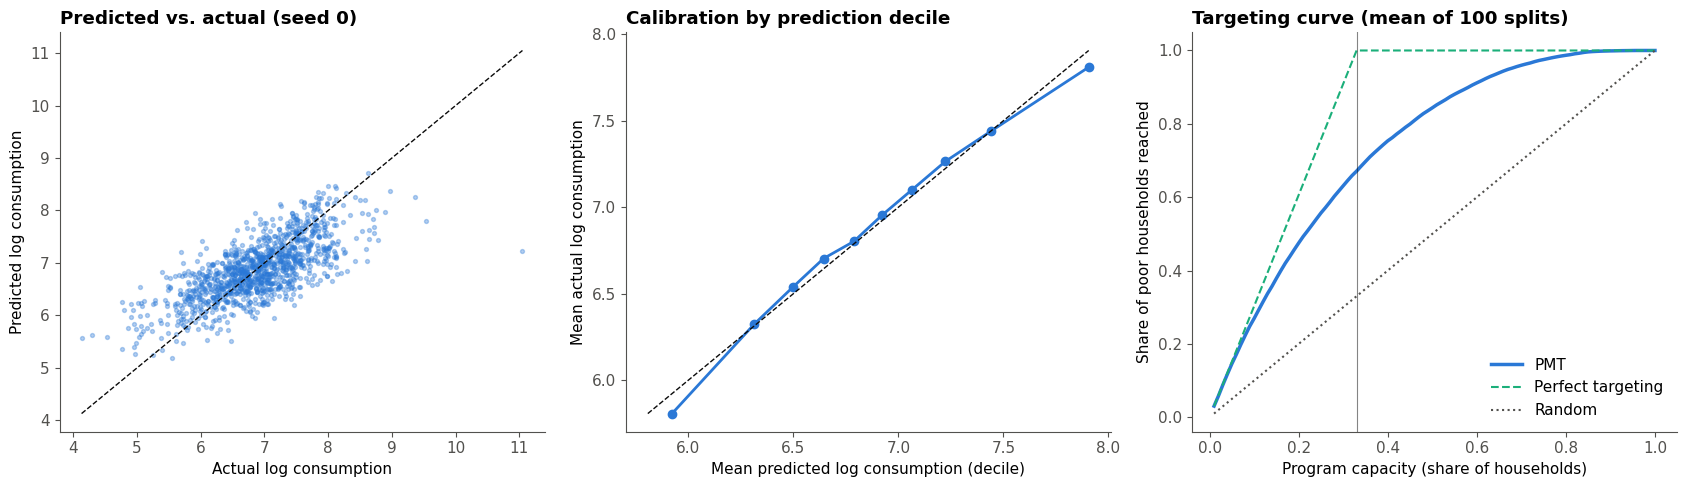

In [ ]:
seed_files = sorted(PRED_DIR.glob('seed_*.csv'))
pmt_runs = [pd.read_csv(f) for f in seed_files]
ex = pmt_runs[0]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

ax = axes[0]
ax.scatter(np.log(ex['ground_truth']), np.log(ex['predictions']), s=8, alpha=0.35, color=BLUE)
lims = [np.log(ex[['ground_truth', 'predictions']].values).min(), np.log(ex[['ground_truth', 'predictions']].values).max()]
ax.plot(lims, lims, color=INK, linestyle='--', linewidth=1)
ax.set_xlabel('Actual log consumption')
ax.set_ylabel('Predicted log consumption')
ax.set_title('Predicted vs. actual (seed 0)', loc='left')

ax = axes[1]
calib = []
for run in pmt_runs:
    d = np.log(run).assign(decile=lambda t: pd.qcut(t['predictions'], 10, labels=False))
    calib.append(d.groupby('decile')[['predictions', 'ground_truth']].mean())
calib = pd.concat(calib).groupby(level=0).mean()
ax.plot(calib['predictions'], calib['ground_truth'], marker='o', color=BLUE, linewidth=2)
lo, hi = calib.values.min(), calib.values.max()
ax.plot([lo, hi], [lo, hi], color=INK, linestyle='--', linewidth=1)
ax.set_xlabel('Mean predicted log consumption (decile)')
ax.set_ylabel('Mean actual log consumption')
ax.set_title('Calibration by prediction decile', loc='left')

ax = axes[2]
caps = np.linspace(0.01, 1.0, 100)
curves = []
for run in pmt_runs:
    n = len(run)
    poor = (run['ground_truth'].rank(method='first') <= round(POVERTY_SHARE * n)).values
    order = np.argsort(run['predictions'].values)
    curves.append([poor[order[:int(round(c * n))]].sum() / poor.sum() for c in caps])
ax.plot(caps, np.mean(curves, axis=0), color=BLUE, linewidth=2.5, label='PMT')
ax.plot(caps, np.minimum(caps / POVERTY_SHARE, 1), color=AQUA, linestyle='--', label='Perfect targeting')
ax.plot(caps, caps, color=MUTED, linestyle=':', label='Random')
ax.axvline(POVERTY_SHARE, color=INK, linewidth=0.8, alpha=0.5)
ax.set_xlabel(r'Program capacity (share of households)')
ax.set_ylabel('Share of poor households reached')
ax.set_title('Targeting curve (mean of 100 splits)', loc='left')
ax.legend(frameon=False, loc='lower right')

plt.tight_layout()
plt.show()

## Allocation problem

Same setup as the replication repo. The planner ranks households by predicted consumption (poorest first). `utility` is CRRA welfare gain with ρ = 3; `utility_step` counts how many households below the 33% poverty line are reached. `AllocationData` averages every welfare number over the first 25 splits (set `N_RVP_SPLITS = 100` to use all of them; it is about 4x slower).

In [ ]:
from rvp import (AllocationData, AllocationProblem, BenefitDimension, CapacityDimension,
                 CostSurface, DataLabelingDimension, DesignSpace, plot_welfare_surface)
from rvp.constraints import CoverageConstraint
from rvp.policies import RankingPolicy
from rvp.utilities import CRRAUtility, PartitionedUtility
from rvp.comparison import optimize_budget_frontier
from rvp.design.dimensions.data_labeling import DataLabelingDimension
from rvp.design.space import DesignSpace as _DesignSpace

# Speed-ups (same results): every welfare_at() call used to copy all splits and rebuild AllocationData,
# and every Q1/Q2/Q3 plot recomputed an identical 900-point surface. Cache both.
_orig_label_at = DataLabelingDimension.at
def _cached_label_at(self, problem, theta):
    cache = self.__dict__.setdefault('_data_cache', {})
    key = round(float(theta), 12)
    if key not in cache:
        cache[key] = _orig_label_at(self, problem, theta).data
    return AllocationProblem(data=cache[key], utility=problem.utility,
                             constraint=problem.constraint, policy=problem.policy)
DataLabelingDimension.at = _cached_label_at

_orig_surface = getattr(_DesignSpace, '_orig_welfare_surface', _DesignSpace.welfare_surface)
_DesignSpace._orig_welfare_surface = _orig_surface
_surface_cache = {}
def _cached_surface(self, dim_x, dim_y, fixed=None, n=50, metric='mean_utility', subgroup_mask=None):
    if subgroup_mask is not None:
        return _orig_surface(self, dim_x, dim_y, fixed, n, metric, subgroup_mask)
    key = (self, dim_x, dim_y, tuple(sorted((fixed or {}).items(), key=lambda kv: id(kv[0]))), n, metric)
    if key not in _surface_cache:
        _surface_cache[key] = _orig_surface(self, dim_x, dim_y, fixed, n, metric)
    x, y, W = _surface_cache[key]
    return x.copy(), y.copy(), W.copy()
_DesignSpace.welfare_surface = _cached_surface

# The repo uses LaTeX text rendering; Colab has no LaTeX install, so keep it off
plt.rcParams.update({'text.usetex': False, 'font.size': 14, 'axes.labelsize': 16, 'axes.titlesize': 16,
                     'xtick.labelsize': 13, 'ytick.labelsize': 13, 'legend.fontsize': 12})

# Welfare surfaces re-rank every split at every grid point, which is slow with 100 splits
# (~3.5 min per surface). Averaging over 25 splits gives near-identical surfaces ~4x faster.
N_RVP_SPLITS = 25
data = AllocationData(df=pmt_runs[:N_RVP_SPLITS])

BASE_BENEFIT = 100
RHO = 3.0
COST_PER_LABEL = 13

policy = RankingPolicy(ascending=True)
utility = CRRAUtility(rho=RHO, b=BASE_BENEFIT)
utility_step = PartitionedUtility(thresholds=[POVERTY_SHARE], values=[1, 0], threshold_type='percentile')
constraint = CoverageConstraint(max_coverage=1.0, population_size=data.n)

base_problem = AllocationProblem(data=data, utility=utility, constraint=constraint, policy=policy)
base_problem_step = AllocationProblem(data=data, utility=utility_step, constraint=constraint, policy=policy)

print(f'{data.n_datasets} splits x {data.n} test households each')
base_problem.evaluate()

25 splits x 1174 test households each


{'total_utility': 0.0014188832380719865,
 'mean_utility': 1.2085887888177056e-06,
 'utility_ratio': 1.0,
 'n_allocated': 1174.0,
 'actions': None}

## Design space

Three levers: capacity α (share of households that receive a transfer), benefit b (transfer size), and label fraction (share of households with PMT data collected; the rest get the population-mean score and are ranked at random).

In [ ]:
capacity_dim = CapacityDimension(bounds=(0.01, 1.0), name=r'Capacity ($\alpha$)')
benefit_dim = BenefitDimension(bounds=(1, 1000), name=r'Benefit ($b$)')
labeling_dim = DataLabelingDimension(base_problem=base_problem, bounds=(0.0, 1.0), seed=42,
                                     name='Label Fraction', unlabeled_strategy='population_mean')

space = DesignSpace(base_problem=base_problem, dimensions=[capacity_dim, benefit_dim, labeling_dim])
space_step = DesignSpace(base_problem=base_problem_step, dimensions=[capacity_dim, labeling_dim])

welfare_norm = space.welfare_at({capacity_dim: 1.0, benefit_dim: 100, labeling_dim: 1.0}, metric='mean_utility')

cost_surface = CostSurface(lambda config: data.n * (
    float(config[capacity_dim]) * float(BASE_BENEFIT) + float(config[labeling_dim]) * COST_PER_LABEL))

STATUS_QUO = {capacity_dim: 0.05, labeling_dim: 0.20}
space

DesignSpace(dimensions=['Capacity ($\\alpha$)', 'Benefit ($b$)', 'Label Fraction'])

### Relative value of prediction at the status quo

A numeric companion to Q2: the marginal welfare per dollar from a small increase in capacity vs. a small increase in data collection, at 5% capacity and 20% coverage. A ratio above 1 means the next dollar does more good spent on prediction (data) than on capacity.

In [ ]:
def marginal_value_per_dollar(sp, sq, fixed=None, h=0.01):
    fixed = fixed or {}
    base = {**sq, **fixed}
    w0 = sp.welfare_at(base, metric='mean_utility')
    out = {}
    for dim, unit_cost in [(capacity_dim, BASE_BENEFIT), (labeling_dim, COST_PER_LABEL)]:
        w1 = sp.welfare_at({**base, dim: base[dim] + h}, metric='mean_utility')
        out[dim.name] = (w1 - w0) / (h * unit_cost)
    out['Ratio (data / capacity)'] = out['Label Fraction'] / out[capacity_dim.name]
    return out

rvp_table = pd.DataFrame({
    'Step utility (CS1)': marginal_value_per_dollar(space_step, STATUS_QUO),
    'CRRA utility (CS2)': marginal_value_per_dollar(space, STATUS_QUO, fixed={benefit_dim: BASE_BENEFIT}),
}).T
rvp_table.columns = ['dW/$ capacity', 'dW/$ data', 'Ratio (data / capacity)']
rvp_table

,dW/$ capacity,dW/$ data,Ratio (data / capacity)
Step utility (CS1),4.906303e-03,4.979688e-03,1.014957
CRRA utility (CS2),5.853731e-09,1.664561e-07,28.435904


# Case Study 1: Step-function utility
Welfare = share of households below the poverty line (33%) who are reached.

## (Q1) Local rate of improvement

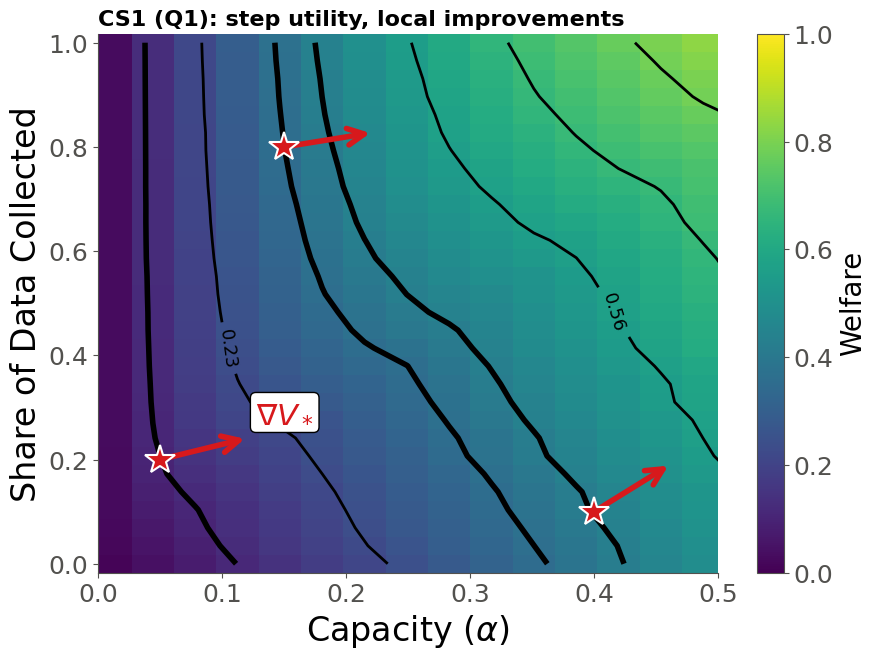

In [ ]:
fig, ax = plot_welfare_surface(
    space_step, dim_x=capacity_dim, dim_y=labeling_dim, welfare_metric='mean_utility', normalize='max',
    xlim=(0.0, 0.5), n=30,
    status_quo=[{capacity_dim: 0.05, labeling_dim: 0.2}, {capacity_dim: 0.4, labeling_dim: 0.1},
                {capacity_dim: 0.15, labeling_dim: 0.8}],
    cmap='viridis', n_contours=8, cbar_label='Welfare')
ax.set_ylabel('Share of Data Collected')
ax.set_title('CS1 (Q1): step utility, local improvements', loc='left')
plt.show()

## (Q2) Inspecting optimality
The cost overlay shows the iso-cost line through the status quo (\$13 per label, \$100 per transfer).

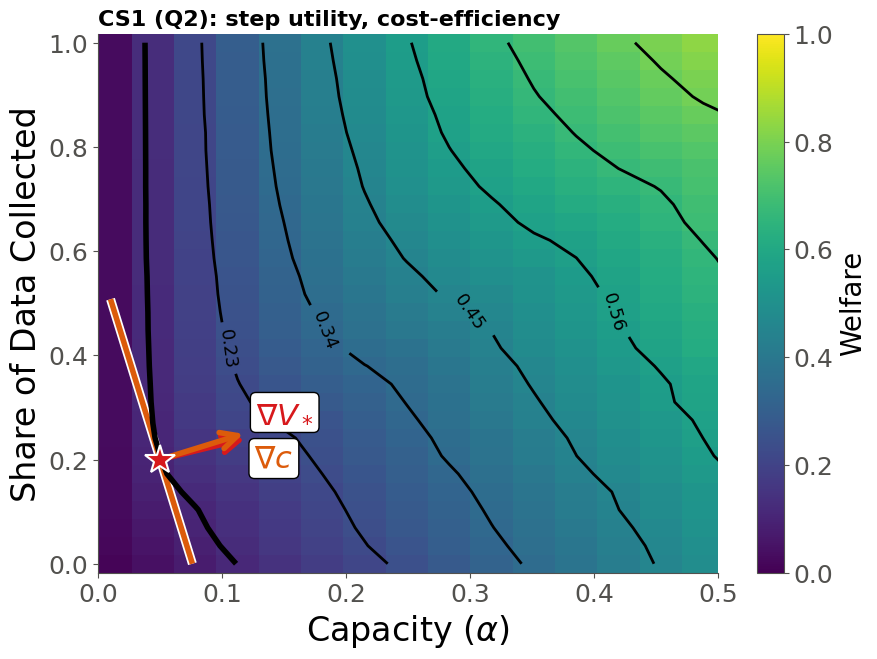

In [ ]:
fig, ax = plot_welfare_surface(
    space_step, dim_x=capacity_dim, dim_y=labeling_dim, welfare_metric='mean_utility', normalize='max',
    xlim=(0.0, 0.5), n=30, status_quo=STATUS_QUO, cmap='viridis', cost_surface=cost_surface,
    n_contours=8, cbar_label='Welfare')
ax.set_ylabel('Share of Data Collected')
ax.set_title('CS1 (Q2): step utility, cost-efficiency', loc='left')
plt.show()

## (Q3) Choosing optimal parameters (expansion path)

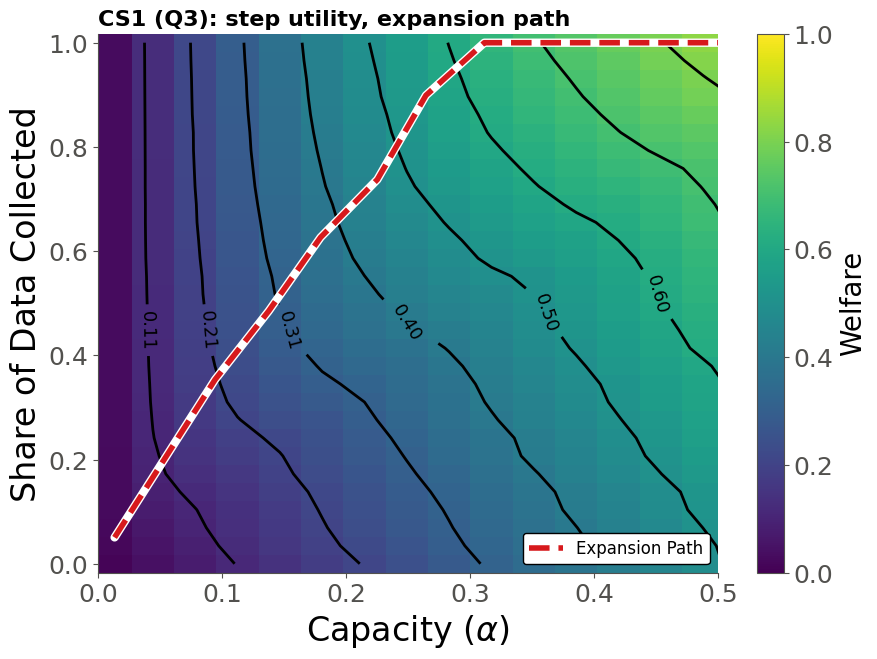

,budget,optimal_welfare,optimal_cost,unspent_budget,optimal_Capacity ($\alpha$)_theta,optimal_Label Fraction_theta
0,1000.000000,0.009574,1000.000000,-4.547474e-13,0.013252,0.050505
1,8071.428571,0.038228,8071.428571,1.818989e-12,0.053789,0.202020
2,15142.857143,0.067734,15142.857143,1.818989e-12,0.094326,0.353535
3,22214.285714,0.096593,22214.285714,0.000000e+00,0.137488,0.484848
4,29285.714286,0.125724,29285.714286,0.000000e+00,0.179338,0.626263
5,36357.142857,0.155264,36357.142857,0.000000e+00,0.225127,0.737374
6,43428.571429,0.184668,43428.571429,7.275958e-12,0.264351,0.898990
7,50500.000000,0.213152,50500.000000,0.000000e+00,0.311453,1.000000
8,57571.428571,0.237649,57571.428571,0.000000e+00,0.371687,1.000000
9,64642.857143,0.257547,64642.857143,7.275958e-12,0.431921,1.000000


In [ ]:
BUDGET_MAX_ADDITIONAL = 100_000
N_BUDGET_POINTS = 15
OPT_GRID_N = (100, 100)
PATH_START = {capacity_dim: 0.01, labeling_dim: 0.01}

budget_results_step, budget_candidates_step = optimize_budget_frontier(
    space=space_step, cost_surface=cost_surface, solve_dim=capacity_dim,
    budget_range=(1000, BUDGET_MAX_ADDITIONAL), n_budget_points=N_BUDGET_POINTS,
    status_quo=PATH_START, n=OPT_GRID_N, welfare_metric='mean_utility', return_candidates=True)

fig, ax = plot_welfare_surface(
    space_step, dim_x=capacity_dim, dim_y=labeling_dim, welfare_metric='mean_utility', n=30,
    normalize='max', cbar_label='Welfare', xlim=(0, 0.5),
    path_results=budget_results_step, path_label='Expansion Path')
ax.set_ylabel('Share of Data Collected')
ax.set_title('CS1 (Q3): step utility, expansion path', loc='left')
plt.show()
budget_results_step.head(N_BUDGET_POINTS)

# Case Study 2: CRRA utility
Welfare = CRRA utility gain (ρ = 3) from a \$100 PPP transfer, which weights gains to the poorest households most.

## (Q1) Local rate of improvement

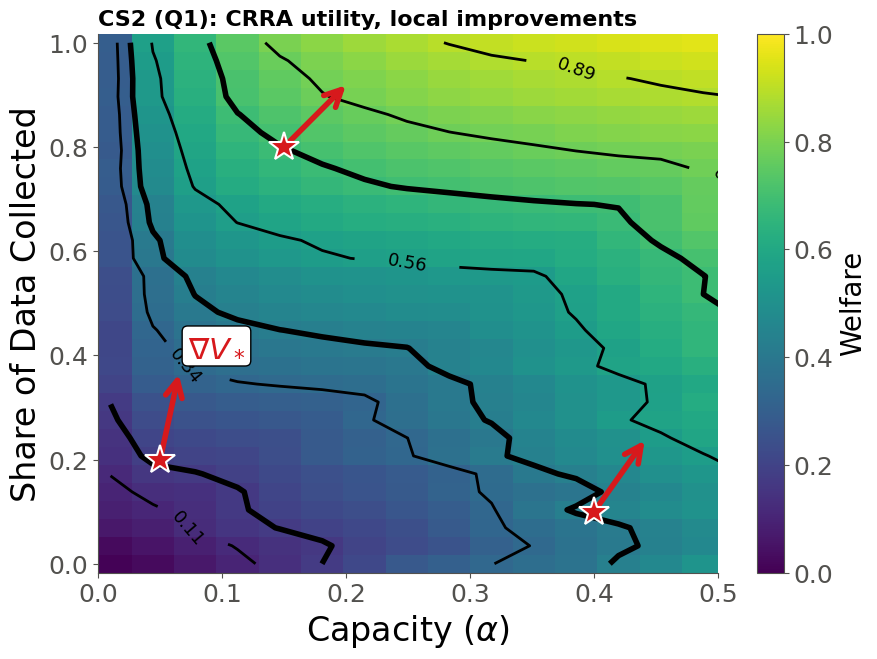

In [ ]:
fig, ax = plot_welfare_surface(
    space, dim_x=capacity_dim, dim_y=labeling_dim, fixed={benefit_dim: BASE_BENEFIT},
    welfare_metric='mean_utility', normalize_by=welfare_norm, n=30, xlim=(0.0, 0.5),
    status_quo=[{capacity_dim: 0.05, labeling_dim: 0.2}, {capacity_dim: 0.4, labeling_dim: 0.1},
                {capacity_dim: 0.15, labeling_dim: 0.8}],
    cmap='viridis', n_contours=8, cbar_label='Welfare')
ax.set_ylabel('Share of Data Collected')
ax.set_title('CS2 (Q1): CRRA utility, local improvements', loc='left')
plt.show()

## (Q2) Inspecting optimality

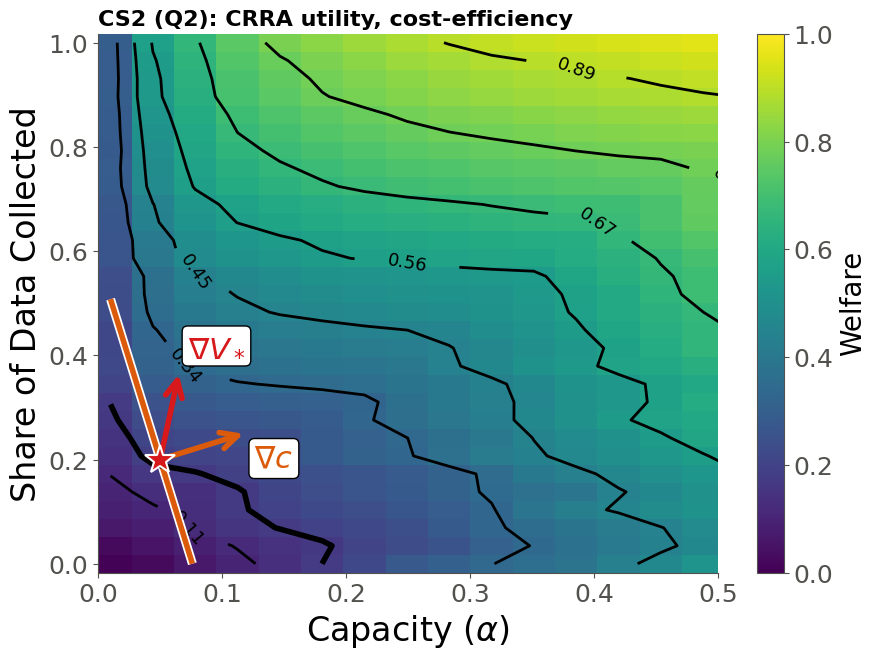

In [ ]:
fig, ax = plot_welfare_surface(
    space, dim_x=capacity_dim, dim_y=labeling_dim, fixed={benefit_dim: BASE_BENEFIT},
    welfare_metric='mean_utility', normalize_by=welfare_norm, xlim=(0.0, 0.5), n=30,
    status_quo=STATUS_QUO, cmap='viridis', cost_surface=cost_surface, n_contours=8, cbar_label='Welfare')
ax.set_ylabel('Share of Data Collected')
ax.set_title('CS2 (Q2): CRRA utility, cost-efficiency', loc='left')
plt.show()

## (Q3) Choosing optimal parameters (expansion path)

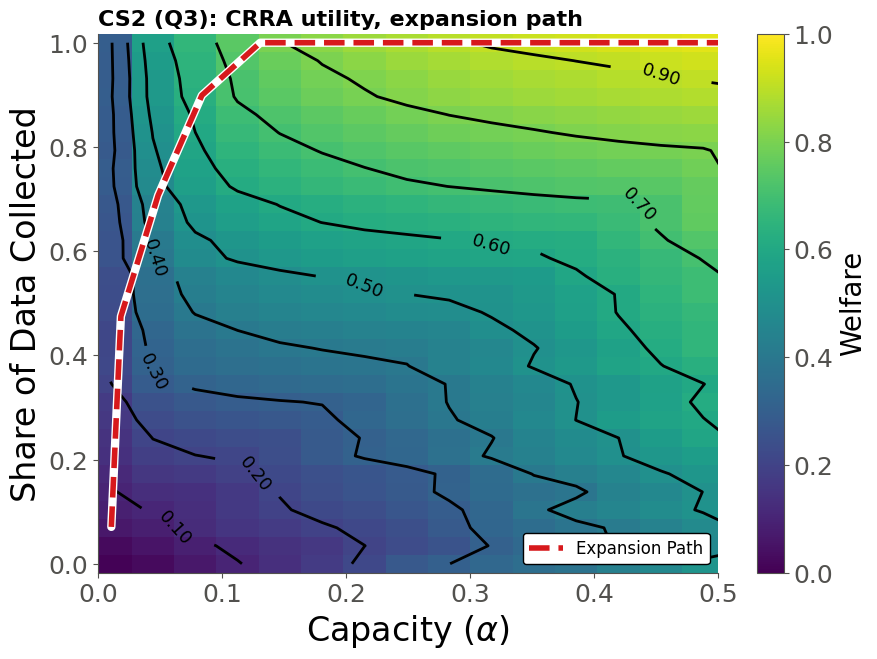

,budget,optimal_welfare,optimal_cost,unspent_budget,optimal_Capacity ($\alpha$)_theta,optimal_Label Fraction_theta
0,1000.000000,7.815858e-08,1000.000000,-4.547474e-13,0.010626,0.070707
1,8071.428571,3.409011e-07,8071.428571,0.000000e+00,0.018334,0.474747
2,15142.857143,5.865525e-07,15142.857143,1.818989e-12,0.048366,0.707071
3,22214.285714,7.823562e-07,22214.285714,3.637979e-12,0.083650,0.898990
4,29285.714286,9.404209e-07,29285.714286,0.000000e+00,0.130752,1.000000
5,36357.142857,1.010970e-06,36357.142857,7.275958e-12,0.190986,1.000000
6,43428.571429,1.055591e-06,43428.571429,7.275958e-12,0.251220,1.000000
7,50500.000000,1.094595e-06,50500.000000,0.000000e+00,0.311453,1.000000
8,57571.428571,1.118220e-06,57571.428571,0.000000e+00,0.371687,1.000000
9,64642.857143,1.138243e-06,64642.857143,7.275958e-12,0.431921,1.000000


In [ ]:
budget_results_crra, budget_candidates_crra = optimize_budget_frontier(
    space=space, cost_surface=cost_surface, solve_dim=capacity_dim,
    budget_range=(1000, BUDGET_MAX_ADDITIONAL), n_budget_points=N_BUDGET_POINTS,
    status_quo={**PATH_START, benefit_dim: BASE_BENEFIT}, fixed={benefit_dim: BASE_BENEFIT},
    n=100, welfare_metric='mean_utility', return_candidates=True)

fig, ax = plot_welfare_surface(
    space, dim_x=capacity_dim, dim_y=labeling_dim, fixed={benefit_dim: BASE_BENEFIT},
    welfare_metric='mean_utility', n=30, normalize='max', cbar_label='Welfare', xlim=(0, 0.5),
    path_results=budget_results_crra, path_label='Expansion Path')
ax.set_ylabel('Share of Data Collected')
ax.set_title('CS2 (Q3): CRRA utility, expansion path', loc='left')
plt.show()
budget_results_crra.head(N_BUDGET_POINTS)

# Case Study 3: Varying transfer size
CRRA utility with data coverage fixed at 20%; the planner trades off how many households get a transfer against how large each transfer is.

In [ ]:
benefit_dim = BenefitDimension(bounds=(1, 500), name='Cash Transfer (PPP USD)')
space = DesignSpace(base_problem=base_problem, dimensions=[capacity_dim, benefit_dim, labeling_dim])

BENEFIT_CAPACITY_WELFARE_SCALE = space.welfare_at(
    {capacity_dim: 1.0, benefit_dim: 500, labeling_dim: 1.0}, metric='mean_utility')
cost_surface_benefit_capacity = CostSurface(
    lambda config: data.n * float(config[capacity_dim]) * float(config[benefit_dim]))
status_quo_benefit_capacity = {capacity_dim: 0.05, benefit_dim: 100}
labeling_dim_fixed = 0.2

## (Q1) Local improvements

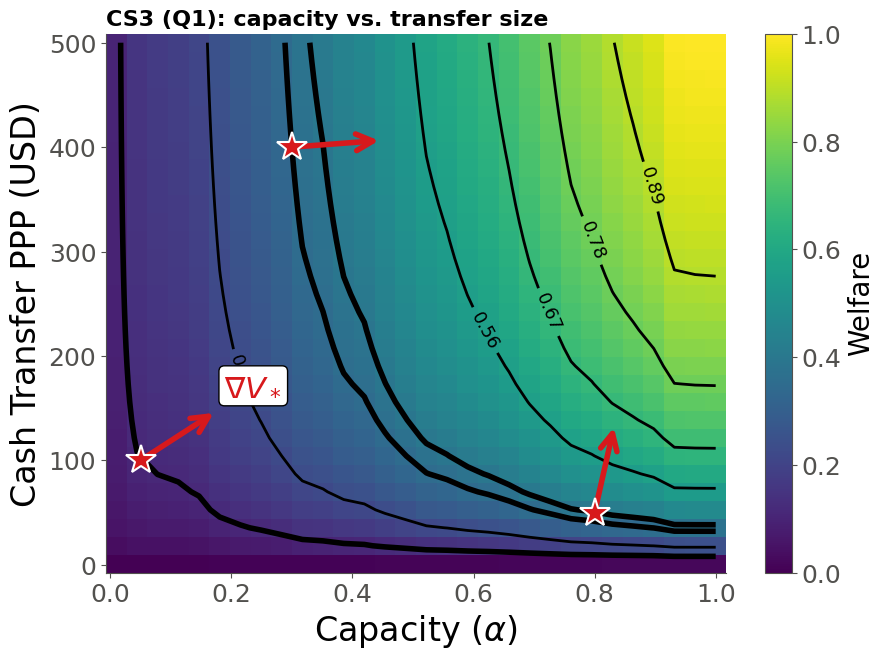

In [ ]:
fig, ax = plot_welfare_surface(
    space, dim_x=capacity_dim, dim_y=benefit_dim,
    status_quo=[status_quo_benefit_capacity, {capacity_dim: 0.8, benefit_dim: 50},
                {capacity_dim: 0.3, benefit_dim: 400}],
    fixed={labeling_dim: labeling_dim_fixed}, welfare_metric='mean_utility',
    normalize_by=BENEFIT_CAPACITY_WELFARE_SCALE, n=30, n_contours=8, cmap='viridis', cbar_label='Welfare')
ax.set_ylabel('Cash Transfer PPP (USD)')
ax.set_title('CS3 (Q1): capacity vs. transfer size', loc='left')
plt.show()

## (Q2) Inspecting optimality

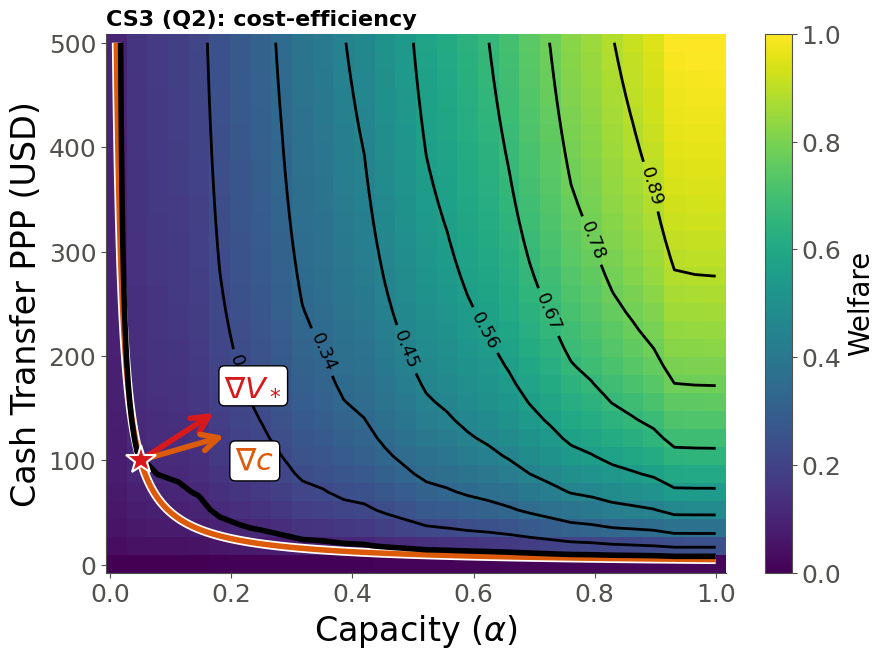

In [ ]:
fig, ax = plot_welfare_surface(
    space, dim_x=capacity_dim, dim_y=benefit_dim, status_quo=status_quo_benefit_capacity,
    cost_surface=cost_surface_benefit_capacity, fixed={labeling_dim: labeling_dim_fixed},
    welfare_metric='mean_utility', normalize_by=BENEFIT_CAPACITY_WELFARE_SCALE, n=30, n_contours=8,
    cmap='viridis', cbar_label='Welfare')
ax.set_ylabel('Cash Transfer PPP (USD)')
ax.set_title('CS3 (Q2): cost-efficiency', loc='left')
plt.show()

## (Q3) Choosing optimal parameters

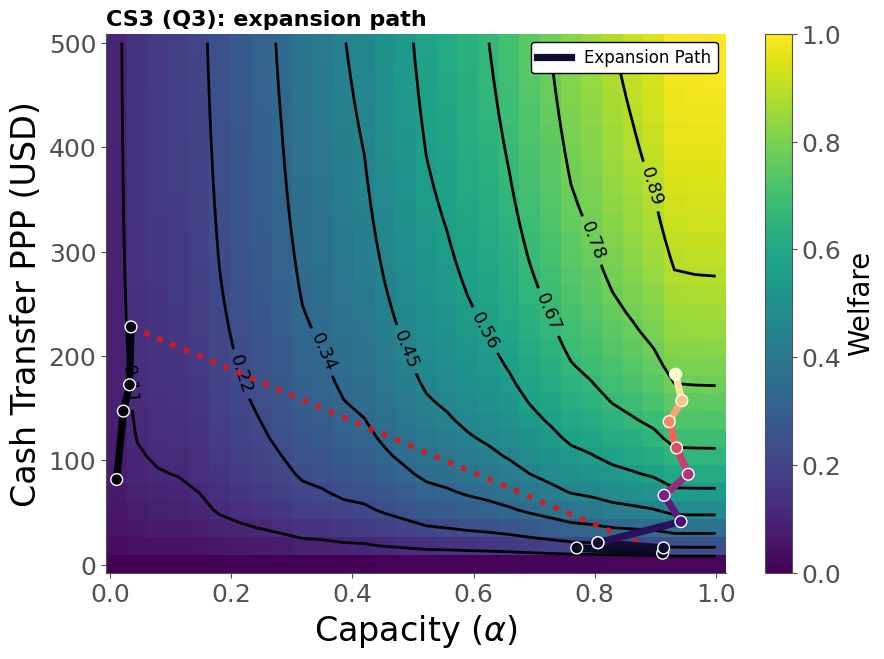

,budget,optimal_Capacity ($\alpha$)_theta,optimal_Cash Transfer (PPP USD)_theta,optimal_welfare
0,1000.000,0.011,81.646,0.0
1,3714.286,0.022,147.172,0.0
2,6428.571,0.032,172.374,0.0
3,9142.857,0.034,227.818,0.0
4,11857.143,0.912,11.081,0.0
5,14571.429,0.771,16.121,0.0
6,17285.714,0.914,16.121,0.0
7,20000.000,0.806,21.162,0.0
8,20000.000,0.806,21.162,0.0
9,45714.286,0.943,41.323,0.0


In [ ]:
budgets = np.concatenate([np.linspace(1000, 20000, 8), np.linspace(20000, 200000, 8)])

budget_results_benefit, budget_candidates_benefit = optimize_budget_frontier(
    space=space, cost_surface=cost_surface_benefit_capacity, solve_dim=capacity_dim, budgets=budgets,
    status_quo={capacity_dim: 0.01, benefit_dim: 1, labeling_dim: labeling_dim_fixed},
    fixed={labeling_dim: labeling_dim_fixed}, n=100, welfare_metric='mean_utility', return_candidates=True)

fig, ax = plot_welfare_surface(
    space, dim_x=capacity_dim, dim_y=benefit_dim, fixed={labeling_dim: labeling_dim_fixed},
    welfare_metric='mean_utility', n=30, normalize_by=BENEFIT_CAPACITY_WELFARE_SCALE,
    cbar_label='Welfare', n_contours=8, path_results=budget_results_benefit, path_label='Expansion Path',
    path_break_threshold=0.18, path_bridge_breaks=True, path_bridge_color='#d7191c',
    path_bridge_alpha=0.95, path_cmap='magma', path_linewidth=5.2, path_underlay_linewidth=0,
    path_linestyle='-', path_marker_size=72, path_legend_loc='upper right')
ax.set_ylabel('Cash Transfer PPP (USD)')
ax.set_title('CS3 (Q3): expansion path', loc='left')
plt.show()

capacity_col = f'optimal_{capacity_dim.name}_theta'
benefit_col = f'optimal_{benefit_dim.name}_theta'
budget_results_benefit[['budget', capacity_col, benefit_col, 'optimal_welfare']].round(3)

# Joint optimization: benefit, data collection, and capacity
All three levers move together, starting from the status quo (5% capacity, \$100 transfer, 20% coverage).

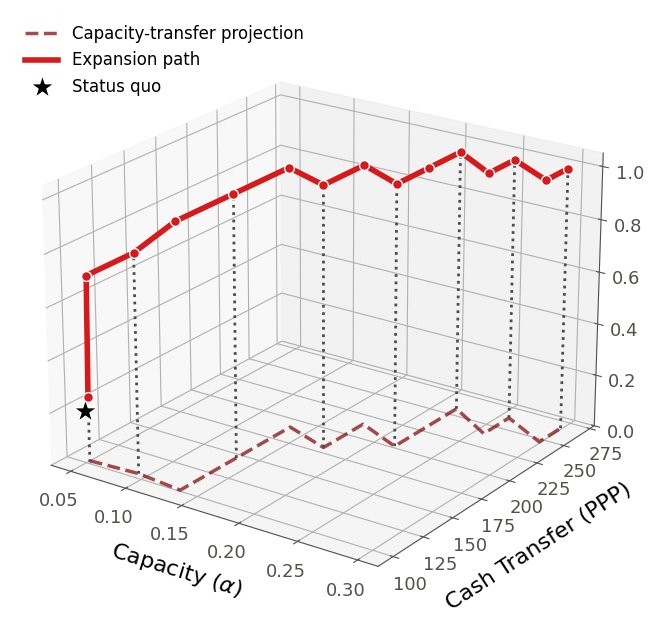

,budget,optimal_Capacity ($\alpha$)_theta,optimal_Cash Transfer (PPP USD)_theta,optimal_Label Fraction_theta,optimal_welfare
0,1000.000,0.051,101.498,0.250,0.0
1,8071.429,0.051,102.767,0.708,0.0
2,15142.857,0.092,104.488,0.833,0.0
3,22214.286,0.134,101.098,1.000,0.0
4,29285.714,0.134,146.133,1.000,0.0
5,36357.143,0.134,191.167,1.000,0.0
6,43428.571,0.175,180.526,1.000,0.0
7,50500.000,0.175,214.945,1.000,0.0
8,57571.429,0.216,201.797,1.000,0.0
9,64642.857,0.216,229.651,1.000,0.0


In [ ]:
soSTATUS_QUO_3D = {capacity_dim: 0.05, benefit_dim: 100, labeling_dim: 0.2}
cost_surface_3d = CostSurface(lambda config: data.n * (
    float(config[capacity_dim]) * float(config[benefit_dim]) + float(config[labeling_dim]) * COST_PER_LABEL))

budget_results_3d, budget_candidates_3d = optimize_budget_frontier(
    space=space, cost_surface=cost_surface_3d, solve_dim=benefit_dim,
    budget_range=(1000, BUDGET_MAX_ADDITIONAL), n_budget_points=15,
    dims=[capacity_dim, benefit_dim, labeling_dim], status_quo=STATUS_QUO_3D,
    n={capacity_dim: 25, labeling_dim: 25}, welfare_metric='mean_utility', return_candidates=True)

labeling_col = f'optimal_{labeling_dim.name}_theta'
path_3d = (budget_results_3d.dropna(subset=['budget', capacity_col, benefit_col, labeling_col])
           .sort_values('budget').reset_index(drop=True))

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
a, b_, l = (path_3d[c].to_numpy(dtype=float) for c in [capacity_col, benefit_col, labeling_col])
ax.plot(a, b_, np.zeros_like(l), color='#7f0000', linestyle='--', linewidth=2.5, alpha=0.7, label='Capacity-transfer projection')
for i in np.unique(np.linspace(0, len(a) - 1, min(8, len(a))).round().astype(int)):
    ax.plot([a[i], a[i]], [b_[i], b_[i]], [0, l[i]], color='#4d4d4d', linestyle=':', linewidth=2)
ax.plot(a, b_, l, color='#d7191c', linewidth=4, label='Expansion path')
ax.scatter(a, b_, l, color='#d7191c', s=50, edgecolor='white', depthshade=False)
ax.scatter([0.05], [100], [0.2], marker='*', s=320, color='black', edgecolor='white', depthshade=False, label='Status quo')
ax.set_xlabel(r'Capacity ($\alpha$)', labelpad=10)
ax.set_ylabel('Cash Transfer (PPP)', labelpad=12)
ax.set_zlabel('Share of Data Collected', labelpad=10)
ax.set_zlim(0, max(0.35, 1.05 * np.nanmax(l)))
ax.view_init(elev=22, azim=-55)
ax.legend(frameon=False, loc='upper left')
plt.show()

path_3d[['budget', capacity_col, benefit_col, labeling_col, 'optimal_welfare']].round(3)